In [10]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.lines as mlines

from transform_data import get_transformed_data, get_shock_mask
from field_config import field_lims, field_labels, field_scales

import flash_amr_tools
import h5py

In [11]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crmhd_vs_mhd_revised"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/updated_outputs"

os.makedirs(fig_dir, exist_ok=True)
# load the bowshock config
bowshock_config = json.load(open("../config/bowshock_config.json", "r"))["config"]


# list of fields we want to plot 1D slice of
fields = [ "dens", "pres"]

# times = [150, 300, 500] * u.kyr
# times = [50, 100, 200] * u.kyr
# times = [30, 90, 120, 180] * u.kyr
times = [60, 100, 300, 500] * u.kyr
times_lss = ["-", "--", ":"]

In [12]:
def get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns):

    field_slice = flash_amr_tools.get_slice(
        field_data,
        pos=0.0,
        axis=2,
        ref_lvl=ref_lvl,
        bbox=bbox,
        bsize=bsize,
        brefs=brefs,
        bns=bns,
    )
    # find zero value of y since we cannot slice again
    y_idx = np.digitize(0.0, yarr, right=True)
    return field_slice[:, y_idx]

def find_hdf5_file_from_time(time, sim_dir):
    """
    Find the HDF5 file corresponding to the given time in the simulation directory.
    """
    for file in os.listdir(sim_dir):
        if file.find("hdf5") != -1:
            pf = h5py.File(os.path.join(sim_dir, file), "r")
            time_from_file = (pf['real scalars'][0][1] * u.s).to(u.kyr)
            if np.isclose(time, time_from_file.value, atol=0.1):
                return os.path.join(sim_dir, file)
            
    return None

In [13]:
# # legend handles

# # time_handles = []
# # initial parameters
# for it, time in enumerate(times):

#     fig = plt.figure(figsize=(9,6))
#     gs = fig.add_gridspec(len(fields), 1, hspace=0, wspace=0.1)
#     axs = gs.subplots(sharex=True, sharey=False)

#     sim_handles = []

#     for sim_name in ["ISM-v30-MHD", "ISM-v30"]:
#         sim_dir = os.path.join(flash_output_dir, bowshock_config[sim_name]["sim_dir"])

#         # find the HDF5 file corresponding to the time
#         sim_file = find_hdf5_file_from_time(time.value, sim_dir)

#         blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

#         # open file to get the coordinate information
#         pf = h5py.File(sim_file, "r")
#         print(f"List of variables in file: {list(pf.keys())}")
#         ref_lvl = pf["refine level"][()][blist]
#         bbox = pf["bounding box"][()][blist]
#         bsize = pf["block size"][()][blist]

#         # get size of x and y
#         cube_size = np.zeros(3, dtype=int)
#         cube_size[0] = int(bns[0]) * 2 ** (brefs[0] - brefs[1] + 3)
#         cube_size[1] = int(bns[1]) * 2 ** (brefs[0] - brefs[1] + 3)
#         cube_size[2] = int(bns[2]) * 2 ** (brefs[0] - brefs[1] + 3)

#         # generate arrays for coordinates
#         low_cor, up_cor = bbox[0, :, 0], bbox[-1, :, 1]
#         dxs = (up_cor - low_cor) / cube_size
#         xarr = (
#             np.linspace(low_cor[0], up_cor[0], cube_size[0], endpoint=False) + 0.5 * dxs[0]
#         )
#         yarr = (
#             np.linspace(low_cor[1], up_cor[1], cube_size[1], endpoint=False) + 0.5 * dxs[1]
#         )

#          # find the termination and outer shock as well
#         outer_shock_data = get_shock_mask(pf, blist, shock="outer")
#         outer_shock_1dslice = get_1dslice(outer_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

#         # for the outer shock we only take the upstream quantity
#         x_outer_shock_arr_lt0 = xarr[(outer_shock_1dslice > 0) & (xarr < 0)]
#         x_outer_shock_arr_gt0 = xarr[(outer_shock_1dslice > 0) & (xarr > 0)]

#         term_shock_data = get_shock_mask(pf, blist, shock="term")
#         term_shock_1dslice = get_1dslice(term_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

#         # for termiatnion shock we take both < 0 and > 0
#         x_term_shock_arr_lt0 = xarr[(term_shock_1dslice > 0) & (xarr < 0)]
#         x_term_shock_arr_gt0 = xarr[(term_shock_1dslice > 0) & (xarr > 0)]

#         print(x_term_shock_arr_lt0, x_term_shock_arr_gt0)

#         # now loop over different fields and plot
#         for i, field in enumerate(fields):
#             field_data = get_transformed_data(pf, field, blist)
#             field_1dslice = get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

#             # plot
#             axs[i].plot(
#                 (xarr * u.cm).to(u.pc),
#                 field_1dslice,
#                 lw=3.0,
#                 color=bowshock_config[sim_name]["color"],
#                 ls="-"
#             )

#             # # plot
#             # axs[i].fill_between(
#             #     (xarr * u.cm).to(u.pc).value,
#             #     y1=0,
#             #     y2=field_lims[field][1],
#             #     # where=(outer_shock_1dslice > 0) & ((xarr * u.cm).to(u.pc).value < 0),
#             #     where=((xarr < x_outer_shock_arr[-1]) & (xarr > x_outer_shock_arr[0])),
#             #     alpha=0.5,
#             #     facecolor=None,
#             #     edgecolor=bowshock_config[sim_name]["color"],
#             #     hatch="//"
#             #     # ls="-"
#             # )

#             # # plot
#             # axs[i].fill_between(
#             #     (xarr * u.cm).to(u.pc).value,
#             #     y1=0,
#             #     y2=field_lims[field][1],
#             #     where=((xarr < x_term_shock_arr_lt0[-1]) & (xarr > x_term_shock_arr_lt0[0])),
#             #     alpha=0.5,
#             #     facecolor=None,
#             #     edgecolor=bowshock_config[sim_name]["color"],
#             #     hatch="|"
#             #     # ls="-"
#             # )

#             # # plot
#             # axs[i].fill_between(
#             #     (xarr * u.cm).to(u.pc).value,
#             #     y1=0,
#             #     y2=field_lims[field][1],
#             #     where=((xarr < x_term_shock_arr_gt0[-1]) & (xarr > x_term_shock_arr_gt0[0])),
#             #     alpha=0.5,
#             #     facecolor=None,
#             #     edgecolor=bowshock_config[sim_name]["color"],
#             #     hatch="|"
#             #     # ls="-"
#             # )

#             # plot
#             axs[i].axvline(
#                 (np.mean(x_outer_shock_arr_lt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls="--",
#                 lw=3.0
#                 # ls="-"
#             )
#             # plot
#             axs[i].axvline(
#                 (np.mean(x_outer_shock_arr_gt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls="--",
#                 lw=3.0
#                 # ls="-"
#             )

#             # plot
#             axs[i].axvline(
#                 (np.mean(x_term_shock_arr_gt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls=":",
#                 lw=3.0
#                 # ls="-"
#             )
#             # plot
#             axs[i].axvline(
#                 (np.mean(x_term_shock_arr_lt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls=":",
#                 lw=3.0
#                 # ls="-"
#             )

#             # limits
#             axs[i].set_xlim(xmin=-15, xmax=30)
#             axs[i].set_ylim(field_lims[field])

#             # scale
#             axs[i].set_yscale(field_scales[field])

#             # labels
#             axs[-1].set_xlabel("$x$ / pc", fontsize=25)
#             axs[i].set_ylabel(field_labels[field], fontsize=25)

#             # ticks
#             axs[i].tick_params(
#                 axis="both",
#                 direction="in",
#                 which="major",
#                 size=8,
#                 labelsize=18,
#                 top=True,
#                 right=True,
#             )
#             axs[i].tick_params(
#                 axis="both",
#                 direction="in",
#                 which="minor",
#                 size=6,
#                 labelsize=16,
#                 top=True,
#                 right=True,
#             )

#         sim_handles.append(
#             mlines.Line2D(
#                 [0], [0], lw=3.0, color=bowshock_config[sim_name]["color"], label=bowshock_config[sim_name]["label"]
#             )
#         )

#         # time_handles.append(
#         #     mlines.Line2D(
#         #         [0], [0], lw=3.0, color="k", label=f"t={time:.0f}", ls=times_lss[it]
#         #     )
#         # )

#     handles = [sim_handles[0], sim_handles[1], mlines.Line2D(
#                 [0], [0], lw=3.0, color="k", label="Outer Shock", ls="--"
#             ),
#             mlines.Line2D(
#                 [0], [0], lw=3.0, color="k", label="Termination Shock", ls=":"
#             )]
#     fig.legend(handles=handles, prop={"size":18}, bbox_to_anchor=[0.8,1.07], ncol=2, handleheight=2.4, labelspacing=0.05, frameon=False, borderaxespad=0.0)

#     axs[0].annotate(f"t={time:.0f}", xy=(18.5, 3e-29), fontsize=24)


# # fig.legend(handles=time_handles, prop={"size":14})

#     fig.savefig(f"{fig_dir}/1dslice_t{time.value}kyr.pdf", dpi=300, bbox_inches="tight")

In [14]:
textpos_y = {
    "dens" : 1e-24,
    "vel" : 5e3,
    "pres" : 5e4,
    "mag" : 1e-5
}

ISM-v40-MHD
/home/kwatanabe/Projects/cr-bowshocks/updated_outputs/ISM-v40-MHD/starISM_hdf5_plt_cnt_0003
minimum position of the region of interest:  [-1.54283879e+20 -7.71419300e+19 -7.71419300e+19]
maximum position of the region of interest:  [1.54283879e+20 7.71419300e+19 7.71419300e+19]
Finding all leaf blocks in given region
2368 2368
Biggest block has refinement level: 4
Highest refinement level in simulation: 6
Highest refinement level in selected box: 6
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 2560
Region extended to:	lower		upper
	x	-1.54283876e+20		+1.54283876e+20
	y	-7.71419293e+19		+7.71419293e+19
	z	-7.71419293e+19		+7.71419293e+19

Region center at:	+0.00000000e+00	+0.00000000e+00	+0.00000000e+00
Given center:		+0.00000000e+00	+0.00000000e+0

/home/kwatanabe/miniconda3/envs/crbowshocks_env/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/kwatanabe/miniconda3/envs/crbowshocks_env/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


/home/kwatanabe/Projects/cr-bowshocks/updated_outputs/ISM-v40-MHD/starISM_hdf5_chk_0003
minimum position of the region of interest:  [-1.54283879e+20 -7.71419300e+19 -7.71419300e+19]
maximum position of the region of interest:  [1.54283879e+20 7.71419300e+19 7.71419300e+19]
Finding all leaf blocks in given region
8948 8948
Biggest block has refinement level: 4
Highest refinement level in simulation: 6
Highest refinement level in selected box: 6
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 10080
Region extended to:	lower		upper
	x	-1.54283879e+20		+1.54283879e+20
	y	-7.71419300e+19		+7.71419300e+19
	z	-7.71419300e+19		+7.71419300e+19

Region center at:	+0.00000000e+00	+0.00000000e+00	+0.00000000e+00
Given center:		+0.00000000e+00	+0.00000000e+00	+0.00000000e+

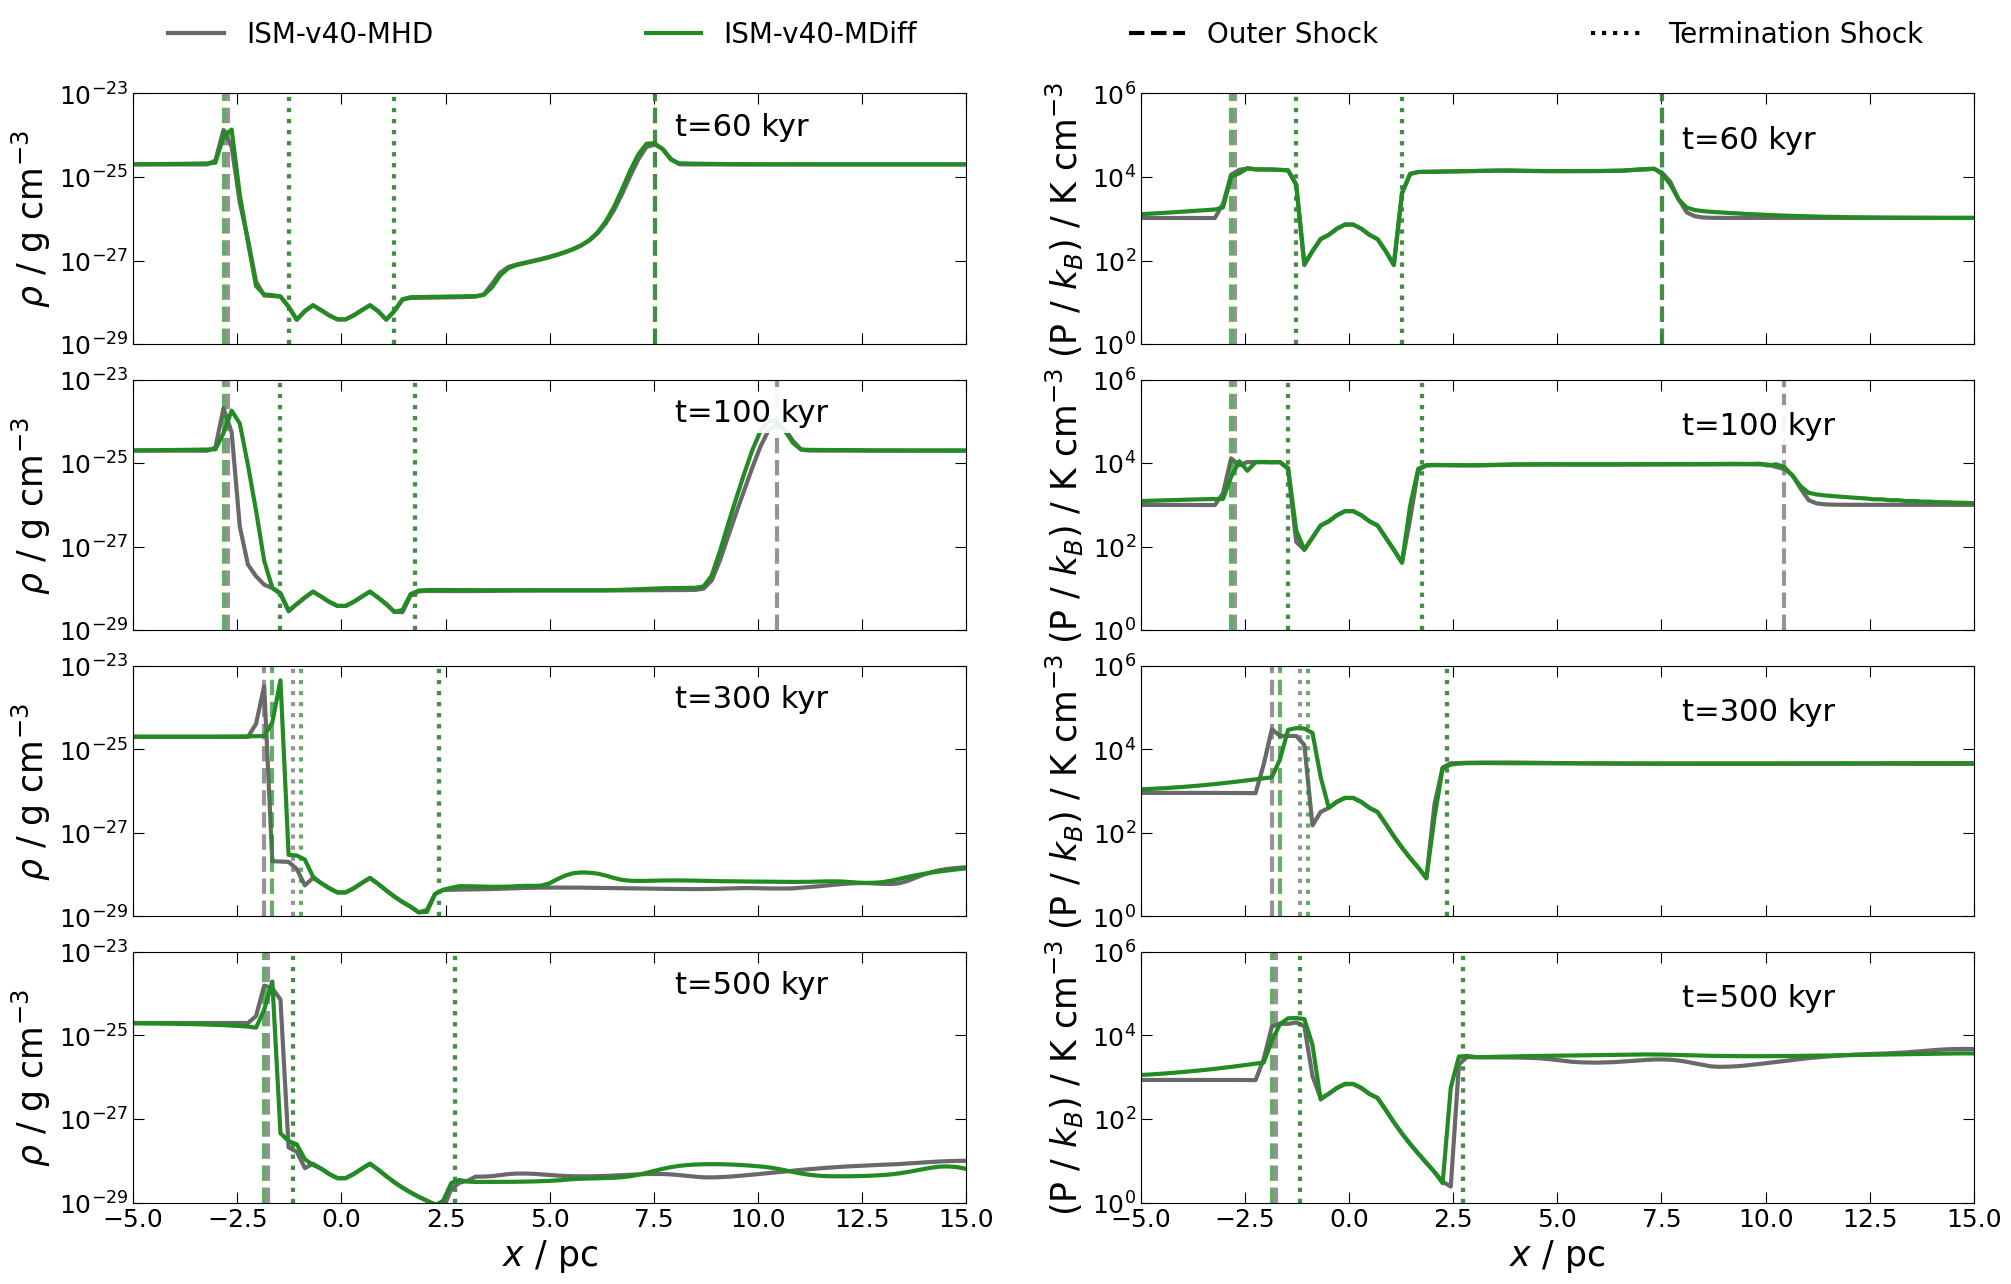

In [15]:
fig = plt.figure(figsize=(20, 12), constrained_layout=True)
gs = fig.add_gridspec(len(times),len(fields), hspace=0, wspace=0.05)
axs = gs.subplots(sharex=True, sharey=False)

axs_flattened = axs.flatten()

# time_handles = []
# initial parameters
for it, time in enumerate(times):

    sim_handles = []

    for sim_name in ["ISM-v40-MHD", "ISM-v40-MDiff"]:
        print(sim_name)
        sim_dir = os.path.join(flash_output_dir, bowshock_config[sim_name]["sim_dir"])

        # find the HDF5 file corresponding to the time
        sim_file = find_hdf5_file_from_time(time.to_value(u.kyr), sim_dir)

        print(sim_file)

        # raise Exception()

        blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

        # open file to get the coordinate information
        pf = h5py.File(sim_file, "r")
        print(f"List of variables in file: {list(pf.keys())}")
        ref_lvl = pf["refine level"][()][blist]
        bbox = pf["bounding box"][()][blist]
        bsize = pf["block size"][()][blist]

        # get size of x and y
        cube_size = np.zeros(3, dtype=int)
        cube_size[0] = int(bns[0]) * 2 ** (brefs[0] - brefs[1] + 3)
        cube_size[1] = int(bns[1]) * 2 ** (brefs[0] - brefs[1] + 3)
        cube_size[2] = int(bns[2]) * 2 ** (brefs[0] - brefs[1] + 3)

        # generate arrays for coordinates
        low_cor, up_cor = bbox[0, :, 0], bbox[-1, :, 1]
        dxs = (up_cor - low_cor) / cube_size
        xarr = (
            np.linspace(low_cor[0], up_cor[0], cube_size[0], endpoint=False) + 0.5 * dxs[0]
        )
        yarr = (
            np.linspace(low_cor[1], up_cor[1], cube_size[1], endpoint=False) + 0.5 * dxs[1]
        )

         # find the termination and outer shock as well
        outer_shock_data = get_shock_mask(pf, blist, shock="outer")
        outer_shock_1dslice = get_1dslice(outer_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

        # raise Exception()

        # for the outer shock we only take the upstream quantity
        x_outer_shock_arr_lt0 = xarr[(outer_shock_1dslice > 0) & (xarr < 0)]
        x_outer_shock_arr_gt0 = xarr[(outer_shock_1dslice > 0) & (xarr > 0)]

        print(x_outer_shock_arr_lt0, x_outer_shock_arr_gt0)

        term_shock_data = get_shock_mask(pf, blist, shock="term")
        term_shock_1dslice = get_1dslice(term_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

        # for termiatnion shock we take both < 0 and > 0
        x_term_shock_arr_lt0 = xarr[(term_shock_1dslice > 0) & (xarr < 0)]
        x_term_shock_arr_gt0 = xarr[(term_shock_1dslice > 0) & (xarr > 0)]

        # now loop over different fields and plot
        for i, field in enumerate(fields):
            field_data = get_transformed_data(pf, field, blist)
            field_1dslice = get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

            # plot
            axs_flattened[2 * it + i].plot(
                (xarr * u.cm).to(u.pc),
                field_1dslice,
                lw=3.0,
                color=bowshock_config[sim_name]["color"],
                ls="-"
            )

            # plot
            axs_flattened[2 * it + i].axvline(
                (np.mean(x_outer_shock_arr_lt0) * u.cm).to(u.pc).value,
                alpha=0.7,
                color=bowshock_config[sim_name]["color"],
                ls="--",
                lw=3.0
                # ls="-"
            )
            # plot
            axs_flattened[2 * it + i].axvline(
                (np.mean(x_outer_shock_arr_gt0) * u.cm).to(u.pc).value,
                alpha=0.7,
                color=bowshock_config[sim_name]["color"],
                ls="--",
                lw=3.0
                # ls="-"
            )

            # plot
            axs_flattened[2 * it + i].axvline(
                (np.mean(x_term_shock_arr_gt0) * u.cm).to(u.pc).value,
                alpha=0.7,
                color=bowshock_config[sim_name]["color"],
                ls=":",
                lw=3.0
                # ls="-"
            )
            # plot
            axs_flattened[2 * it + i].axvline(
                (np.mean(x_term_shock_arr_lt0) * u.cm).to(u.pc).value,
                alpha=0.7,
                color=bowshock_config[sim_name]["color"],
                ls=":",
                lw=3.0
                # ls="-"
            )

            # limits
            axs_flattened[2 * it + i].set_xlim(xmin=-5, xmax=15)
            axs_flattened[2 * it + i].set_ylim(field_lims[field])

            # scale
            axs_flattened[2 * it + i].set_yscale(field_scales[field])

            # labels
            axs_flattened[2 * it + i].set_ylabel(field_labels[field], fontsize=25)

            # ticks
            axs_flattened[2 * it + i].tick_params(
                axis="both",
                direction="in",
                which="major",
                size=8,
                labelsize=18,
                top=True,
                right=True,
            )
            axs_flattened[2 * it + i].tick_params(
                axis="both",
                direction="in",
                which="minor",
                size=6,
                labelsize=16,
                top=True,
                right=True,
            )

            axs_flattened[2 * it + i].annotate(f"t={time.value:.0f} kyr", xy=(8, textpos_y[field]), fontsize=22, bbox=dict(fc="white", ec="none", alpha=0.7), )

            if (2 * it + i) >= 6:  # TODO: change this to a more general condition
                axs_flattened[2 * it + i].set_xlabel("$x$ / pc", fontsize=25)


        sim_handles.append(
            mlines.Line2D(
                [0], [0], lw=3.0, color=bowshock_config[sim_name]["color"], label=bowshock_config[sim_name]["label"]
            )
        )

        # time_handles.append(
        #     mlines.Line2D(
        #         [0], [0], lw=3.0, color="k", label=f"t={time:.0f}", ls=times_lss[it]
        #     )
        # )

# handles = [sim_handles[0], sim_handles[1], mlines.Line2D(
#             [0], [0], lw=3.0, color="k", label="Outer Shock", ls="--"
#         ),
#         mlines.Line2D(
#             [0], [0], lw=3.0, color="k", label="Termination Shock", ls=":"
#         )]
sim_handles.append(
    mlines.Line2D(
        [0], [0], lw=3.0, color="k", label="Outer Shock", ls="--"
    )
)
sim_handles.append(
    mlines.Line2D(
        [0], [0], lw=3.0, color="k", label="Termination Shock", ls=":"
    )
)
fig.legend(handles=sim_handles, prop={"size":20},  ncol=4, frameon=False, borderaxespad=4.0, mode='expand', loc="upper left", bbox_to_anchor=(0.02, 1.15, 1, 0),)
# fig.subplots_adjust(top=0.88)
# axs_flattened[6].set_xlabel("$x$ / pc", fontsize=25)

#     axs[0].annotate(f"t={time:.0f}", xy=(18.5, 3e-29), fontsize=24)


# # fig.legend(handles=time_handles, prop={"size":14})

fig.savefig(f"{fig_dir}/1dslice_all.pdf", dpi=300, bbox_inches="tight")

In [16]:
# # fig = plt.figure(figsize=(20, 12), constrained_layout=True)
# # gs = fig.add_gridspec(len(times),len(fields), hspace=0, wspace=0.05)
# # axs = gs.subplots(sharex=True, sharey=False)

# # axs_flattened = axs.flatten()

# # time_handles = []
# # initial parameters
# for it, time in enumerate(np.arange(0, 190, 10)):
#     time = time * u.kyr

#     # sim_handles = []

#     for i, field in enumerate(fields):

#         # fig = plt.figure(figsize=(20, 12), constrained_layout=True)
#         fig, ax = plt.subplots(figsize=(10,6))

#         for sim_name in ["ISM-v30-MDiff", "ISM-v30", "ISM-v30-HDiff", "ISM-v30-MHD"]:
#             print(sim_name)
#             sim_dir = os.path.join(flash_output_dir, bowshock_config[sim_name]["sim_dir"])

#             # find the HDF5 file corresponding to the time
#             sim_file = find_hdf5_file_from_time(time.to_value(u.kyr), sim_dir)

#             print(sim_file)

#             # raise Exception()

#             blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

#             # open file to get the coordinate information
#             pf = h5py.File(sim_file, "r")
#             print(f"List of variables in file: {list(pf.keys())}")
#             ref_lvl = pf["refine level"][()][blist]
#             bbox = pf["bounding box"][()][blist]
#             bsize = pf["block size"][()][blist]

#             # get size of x and y
#             cube_size = np.zeros(3, dtype=int)
#             cube_size[0] = int(bns[0]) * 2 ** (brefs[0] - brefs[1] + 3)
#             cube_size[1] = int(bns[1]) * 2 ** (brefs[0] - brefs[1] + 3)
#             cube_size[2] = int(bns[2]) * 2 ** (brefs[0] - brefs[1] + 3)

#             # generate arrays for coordinates
#             low_cor, up_cor = bbox[0, :, 0], bbox[-1, :, 1]
#             dxs = (up_cor - low_cor) / cube_size
#             xarr = (
#                 np.linspace(low_cor[0], up_cor[0], cube_size[0], endpoint=False) + 0.5 * dxs[0]
#             )
#             yarr = (
#                 np.linspace(low_cor[1], up_cor[1], cube_size[1], endpoint=False) + 0.5 * dxs[1]
#             )

#             # find the termination and outer shock as well
#             outer_shock_data = get_shock_mask(pf, blist, shock="outer")
#             outer_shock_1dslice = get_1dslice(outer_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

#             # raise Exception()

#             # for the outer shock we only take the upstream quantity
#             x_outer_shock_arr_lt0 = xarr[(outer_shock_1dslice > 0) & (xarr < 0)]
#             x_outer_shock_arr_gt0 = xarr[(outer_shock_1dslice > 0) & (xarr > 0)]

#             print(x_outer_shock_arr_lt0, x_outer_shock_arr_gt0)

#             term_shock_data = get_shock_mask(pf, blist, shock="term")
#             term_shock_1dslice = get_1dslice(term_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

#             # for termiatnion shock we take both < 0 and > 0
#             x_term_shock_arr_lt0 = xarr[(term_shock_1dslice > 0) & (xarr < 0)]
#             x_term_shock_arr_gt0 = xarr[(term_shock_1dslice > 0) & (xarr > 0)]

#         # now loop over different fields and plot
#             field_data = get_transformed_data(pf, field, blist)
#             field_1dslice = get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

#             # plot
#             ax.plot(
#                 (xarr * u.cm).to(u.pc),
#                 field_1dslice,
#                 lw=3.0,
#                 color=bowshock_config[sim_name]["color"],
#                 ls="-"
#             )

#             # plot
#             ax.axvline(
#                 (np.mean(x_outer_shock_arr_lt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls="--",
#                 lw=3.0
#                 # ls="-"
#             )
#             # plot
#             ax.axvline(
#                 (np.mean(x_outer_shock_arr_gt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls="--",
#                 lw=3.0
#                 # ls="-"
#             )

#             # plot
#             ax.axvline(
#                 (np.mean(x_term_shock_arr_gt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls=":",
#                 lw=3.0
#                 # ls="-"
#             )
#             # plot
#             ax.axvline(
#                 (np.mean(x_term_shock_arr_lt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls=":",
#                 lw=3.0
#                 # ls="-"
#             )

#             # limits
#             ax.set_xlim(xmin=-15, xmax=30)
#             ax.set_ylim(field_lims[field])

#             # scale
#             ax.set_yscale(field_scales[field])

#             # labels
#             ax.set_ylabel(field_labels[field], fontsize=25)

#             # ticks
#             ax.tick_params(
#                 axis="both",
#                 direction="in",
#                 which="major",
#                 size=8,
#                 labelsize=18,
#                 top=True,
#                 right=True,
#             )
#             ax.tick_params(
#                 axis="both",
#                 direction="in",
#                 which="minor",
#                 size=6,
#                 labelsize=16,
#                 top=True,
#                 right=True,
#             )

#             ax.annotate(f"t={time.value:.0f} kyr", xy=(20, textpos_y[field]), fontsize=22)

#             ax.set_xlabel("$x$ / pc", fontsize=25)

#         # fig.savefig(f"{fig_dir}/1dslice_{field}_t{int(time.value):03d}.png", dpi=300, bbox_inches="tight")